# 06 · Scientific Results in Cells (MATH_LONG)

**NHyDB 0.27.1 notebook series · v1**

In notebook 05 a formula decided *where* a text goes. Here the roles are different: the **results of a computation are the content** of the cells, and the address comes from the parameters of the computation. A long calculation can be stored stage by stage, survive an interruption and continue exactly where it stopped – without any bookkeeping table.

> **Who is this for?** This notebook starts with a short introduction and continues with runnable examples. **New to NHyDB?** Read from top to bottom – every idea is introduced before it is used. **Already know the basics?** Skip the sections marked 📘 *Background* and jump to the experiments marked ▶. All cells run from top to bottom; optional deep dives are marked ⏩ *Advanced*.

**What you will learn**

* the pattern: parameters / run id → address, computed result → payload
* how to compute in stages, commit, survive an interruption and resume only the missing results
* what happens on a re-run: conflict instead of duplicate, and what `overwrite` really means
* why a formula with many variables (`u = x1 + x2 + x3`) can collide – and how to make it unique
* exact decimal inputs and the NL/NR pair: value on one lane, metadata on the other

**Recommended before:** [05 · MATH_MAP](05_math_map_text_and_formula_lab_v1.ipynb).

### Setup

The next cell checks the environment and defines a few small plotting helpers used in
this notebook. It is collapsed because it is not about NHyDB itself – feel free to open
it. Every database in this notebook lives in a temporary folder that is removed at
the end.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.27.1"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})


def kind_of(n):
    """'NL', 'NR', 'GZ' or 'N0' for a natural number n >= 1 (computed by NHyDB)."""
    try:
        return nhydb.n_to_dynadron_address(n)["lane_name"]
    except nhydb.AddressError:
        return "GZ" if math.isqrt(n) ** 2 == n else "N0"


def group_of(n):
    """The group G whose interval [G(G-1), G(G+1)) contains n."""
    g = math.isqrt(n)
    return g + 1 if n - g * g >= g else g       # N0(g+1) and the NL cells of g+1 lie above g² + g − 1


KIND_LABEL = {"NL": "NL cell", "NR": "NR cell", "GZ": "GZ point (G²)", "N0": "N0 point (G·(G−1))"}

import time
from decimal import Decimal

import pandas as pd
from nhydb.math import MathMap, MathMapLayoutSpec, dry_run

Python 3.14.5 · nhydb 0.27.1 · file format 0.16 · matplotlib 3.11.2


## 📘 Background: two ways to use formulas

> **About the name:** *MATH_LONG* is our working name for this **application pattern**. It is
> **not** a function or a layout type of NHyDB – everything here uses the ordinary MATH layouts
> from notebook 05.

| | MATH_MAP (notebook 05) | Scientific results (this notebook) |
|---|---|---|
| the formula gives | the **place** of a value | the **place** of a result |
| the payload is | any data (a text, a file) | the **result of a computation** |
| the address comes from | input numbers such as a piece index | the **parameters** of the computation or a run id |
| typical use | scatter and reassemble data | long or very many computations, stored for later |

The important rule: **the address must not depend on the result.** It is computed from the
parameters *before* the calculation runs – so later anyone can find a result by knowing only
the parameters, and nobody needs a list of "what has been computed where".

## 1 · The computation: a prime census of the Dynadron rows

**Question:** How many prime numbers lie in each group `G` of the staircase (notebook 01) –
on the NL side and on the NR side?

For each group `G` we count the primes among its NL cells `G² − G + 1 … G² − 1` and among its
NR cells `G² + 1 … G² + G − 1`. That is a deterministic integer computation: the same `G` always
gives the same result. (Imagine each result took hours on a cluster – the pattern is the same.)

In [2]:
def is_prime(n):
    if n < 2:
        return False
    if n % 2 == 0:
        return n == 2
    for p in range(3, math.isqrt(n) + 1, 2):
        if n % p == 0:
            return False
    return True


def prime_census(G):
    """(primes among the NL cells, primes among the NR cells) of group G."""
    nl = sum(is_prime(n) for n in range(G * G - G + 1, G * G))
    nr = sum(is_prime(n) for n in range(G * G + 1, G * G + G))
    return nl, nr


print("G = 24:", prime_census(24), "  (NL cells 553 … 575, NR cells 577 … 599)")

G = 24: (4, 4)   (NL cells 553 … 575, NR cells 577 … 599)


### The address: parameters → cell

The parameters are the group `G` and the half `part` (0 = NL side, 1 = NR side). We let the
formula put the two results of one group on **the same `(u, v)` – one on each lane**:

```text
u    = G
V    = 1
side = part          (0 → NL, 1 → NR)
```

So the NL cell of `(u = G, v = 1)` holds the NL count, the NR cell the NR count. The payload
type is `varuint` (an exact non-negative integer).

In [3]:
census_map = MathMap.compile("prime_census", ("G", "part"), u="G", V="1", side="part")
G_MAX = 400                                       # ▶ Try it: number of groups
STAGE = 50                                        # ▶ Try it: groups per stage
groups = list(range(2, G_MAX + 1))

r = dry_run(census_map, [(G, part) for G in groups for part in (0, 1)])
print(f"{r.total} results planned, {r.unique_cells} cells, {r.collisions} collisions, realms {r.logical_realms}")
assert r.collisions == 0 and r.invalid == 0

798 results planned, 798 cells, 0 collisions, realms (1,)


## 2 · Compute in stages – and get interrupted

**Question:** What happens when a long computation is interrupted?

▶ **Run it:** we compute stage by stage and **commit after each stage**. During stage 4 the
"power fails": the results of that stage are written but **not committed**, and the database is
closed without commit – exactly what a crash does.

In [4]:
PATH = db_path("census.nhydb")
CRASH_STAGE = 3                                  # ▶ Try it: stage index (0-based) that is interrupted
stages = [groups[i:i + STAGE] for i in range(0, len(groups), STAGE)]
computed_by = {}                                 # G → which run computed it (for the figure)

db = nhydb.create(PATH)
db.create_math_layout(MathMapLayoutSpec("prime_census", census_map, 64), layout_id=1, payload_type="varuint")
db.commit()
t0 = time.perf_counter()
for i, stage in enumerate(stages):
    rows = []
    for G in stage:
        nl, nr = prime_census(G)
        rows += [((G, 0), nl), ((G, 1), nr)]
    db.put_math_batch(1, rows)                    # written, not yet durable
    if i == CRASH_STAGE:
        print(f"stage {i}: G = {stage[0]} … {stage[-1]} written, but the power fails before commit!")
        db.close(commit=False)                    # like a crash
        break
    db.commit()
    computed_by.update({G: "run 1" for G in stage})
    print(f"stage {i}: G = {stage[0]} … {stage[-1]} committed")
print(f"run 1 ended after {time.perf_counter() - t0:.2f} s")

stage 0: G = 2 … 51 committed
stage 1: G = 52 … 101 committed
stage 2: G = 102 … 151 committed
stage 3: G = 152 … 201 written, but the power fails before commit!
run 1 ended after 0.01 s


### Resume: compute only what is missing

The second run knows only the formula and the parameter range. It asks the database for each
parameter set and computes **only the missing results** – no log file, no "done" table.

In [5]:
db = nhydb.open(PATH)
print(f"reopened; {db.recovered_tail_bytes} uncommitted bytes of the crashed stage were discarded")

missing = [G for G in groups if db.get_math(1, (G, 0)) is None]
print(f"already stored: {len(groups) - len(missing)} groups, missing: {len(missing)} "
      f"(G = {missing[0]} … {missing[-1]})")

t0 = time.perf_counter()
for i in range(0, len(missing), STAGE):
    stage = missing[i:i + STAGE]
    rows = []
    for G in stage:
        nl, nr = prime_census(G)
        rows += [((G, 0), nl), ((G, 1), nr)]
    db.put_math_batch(1, rows, commit=True)
    computed_by.update({G: "run 2 (resume)" for G in stage})
print(f"run 2 computed {len(missing)} groups in {time.perf_counter() - t0:.2f} s")

results = pd.DataFrame([{"G": G, "NL primes": db.get_math(1, (G, 0)), "NR primes": db.get_math(1, (G, 1)),
                         "computed by": computed_by[G]} for G in groups]).set_index("G")
db.close()

assert results.notna().all().all() and len(results) == len(groups)
for G in (2, 24, 137, G_MAX):                    # spot check against a fresh computation
    assert tuple(results.loc[G, ["NL primes", "NR primes"]]) == prime_census(G)
results.loc[[2, 3, 24, 199, 200, 201, G_MAX]]

reopened; 688 uncommitted bytes of the crashed stage were discarded
already stored: 150 groups, missing: 249 (G = 152 … 400)


run 2 computed 249 groups in 0.06 s


,NL primes,NR primes,computed by
G,,,
2,1,1,run 1
3,1,1,run 1
24,4,4,run 1
199,16,19,run 2 (resume)
200,20,20,run 2 (resume)
201,13,20,run 2 (resume)
400,35,33,run 2 (resume)


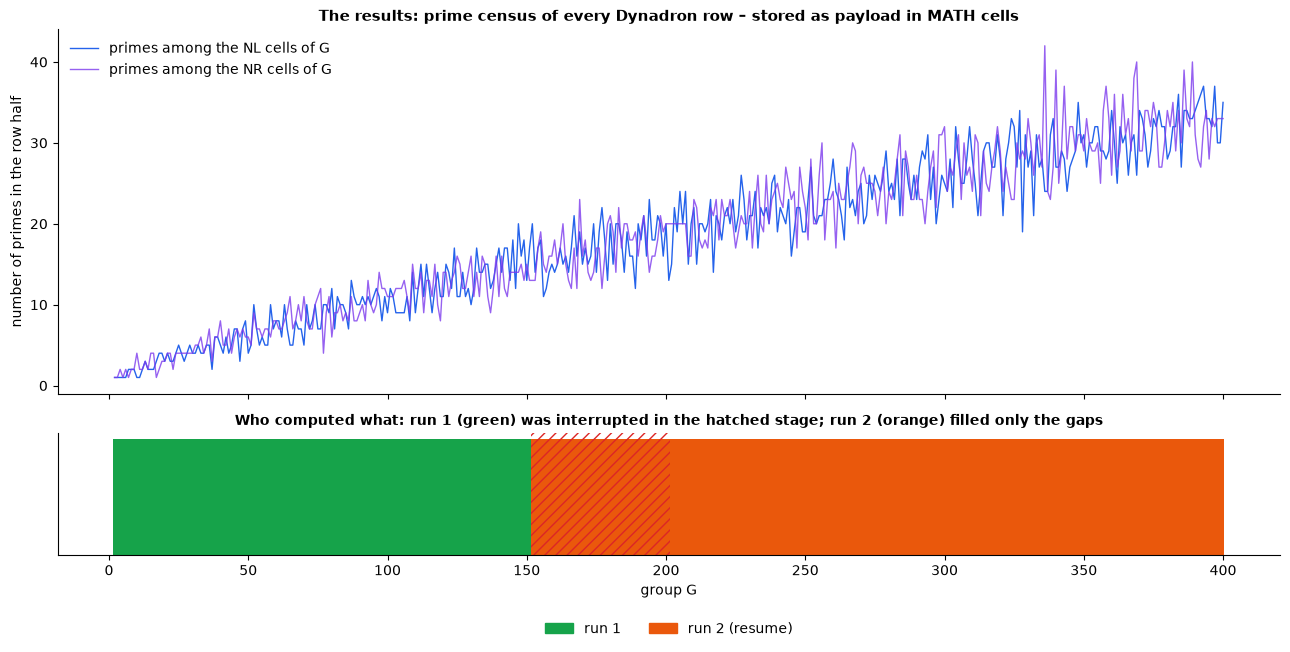

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6.6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(results.index, results["NL primes"], color=COLORS["NL"], lw=1, label="primes among the NL cells of G")
ax1.plot(results.index, results["NR primes"], color=COLORS["NR"], lw=1, alpha=0.8, label="primes among the NR cells of G")
ax1.set_ylabel("number of primes in the row half")
ax1.set_title("The results: prime census of every Dynadron row – stored as payload in MATH cells")
ax1.legend(frameon=False, loc="upper left")

colors = {"run 1": COLORS["ok"], "run 2 (resume)": COLORS["attention"]}
for G in groups:
    ax2.bar(G, 1, width=1, color=colors[computed_by[G]])
crash = stages[CRASH_STAGE]
ax2.axvspan(crash[0] - 0.5, crash[-1] + 0.5, fill=False, hatch="///", edgecolor=COLORS["bad"], lw=0)
ax2.set_yticks([])
ax2.set_xlabel("group G")
ax2.set_title("Who computed what: run 1 (green) was interrupted in the hatched stage; run 2 (orange) filled only the gaps",
              fontsize=10)
handles = [Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax2.legend(handles, list(colors), frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=2)
plt.tight_layout()
plt.show()

**What happened?**

* The committed stages survived the crash; the interrupted stage was discarded completely
  (`recovered_tail_bytes`) – no half-written results.
* The resume found the gaps simply by asking `get_math(layout, parameters)`. **The parameters
  are the bookkeeping.** Run 2 computed only the orange groups.
* The census itself is a small discovery tool: both halves of every row keep containing primes,
  and the counts grow with `G`.

**Ah – results live at addresses that follow from their parameters, so a computation can stop
and continue at any time.**

## 3 · Re-runs: conflict, not duplicate

**Question:** What if someone runs the same computation again – or wants to correct a result?

| situation | behaviour |
|---|---|
| same parameters again | `MathCellConflictError` – there is already a result, nothing is duplicated |
| `overwrite=True` | the new value becomes the current state; the old one stays in the append-only file until a compaction |
| different parameters, same cell | only possible if the formula collides – `dry_run` shows it (section 4) |

In [7]:
with nhydb.open(PATH) as db:
    size_before = os.path.getsize(PATH)
    try:
        db.put_math(1, (24, 0), prime_census(24)[0])
    except nhydb.MathCellConflictError as e:
        print("same run again →", type(e).__name__, ":", e)

    db.put_math(1, (24, 0), 999, overwrite=True, commit=True)    # a deliberately wrong "correction"
    print("after overwrite:", db.get_math(1, (24, 0)))
    db.put_math(1, (24, 0), prime_census(24)[0], overwrite=True, commit=True)
    print("corrected back :", db.get_math(1, (24, 0)))
    assert db.get_math(1, (24, 0)) == prime_census(24)[0]
    print(f"file grew by {os.path.getsize(PATH) - size_before} bytes – old states are kept (append-only)")

same run again → MathCellConflictError : Target cell (1, 24, 1, 0) is already occupied
after overwrite: 999
corrected back : 4
file grew by 768 bytes – old states are kept (append-only)


## 4 · Many variables: `u = x1 + x2 + x3`, `V = t + w + k + d`

**Question:** An experiment has seven parameters. Can we simply add them up to get an address?

The idea is attractive – but **sums forget information**: `(1, 2, 3)` and `(3, 2, 1)` have the
same sum. `dry_run` makes this visible before anything is written.

In [8]:
import itertools

VALUES = (1, 2, 3)                                # ▶ Try it: values each parameter can take
params = list(itertools.product(VALUES, repeat=7))   # (x1, x2, x3, t, w, k, d)
names = ("x1", "x2", "x3", "t", "w", "k", "d")

sum_map = MathMap.compile("sums", names, u="x1 + x2 + x3", V="t + w + k + d", side="NR")
r_sum = dry_run(sum_map, params)
print(f"sums      : {r_sum.total} parameter sets → {r_sum.unique_cells} cells, {r_sum.collisions} collisions")

# Collision-free alternative: positional encoding with a fixed base larger than every value.
B = max(VALUES) + 1
digit_map = MathMap.compile("digits", names, u=f"(x1 * {B} + x2) * {B} + x3",
                            V=f"((t * {B} + w) * {B} + k) * {B} + d", side="NR")
r_dig = dry_run(digit_map, params)
print(f"positional: {r_dig.total} parameter sets → {r_dig.unique_cells} cells, {r_dig.collisions} collisions")
assert r_sum.collisions > 0 and r_dig.collisions == 0

sums      : 2187 parameter sets → 63 cells, 2124 collisions
positional: 2187 parameter sets → 2187 cells, 0 collisions


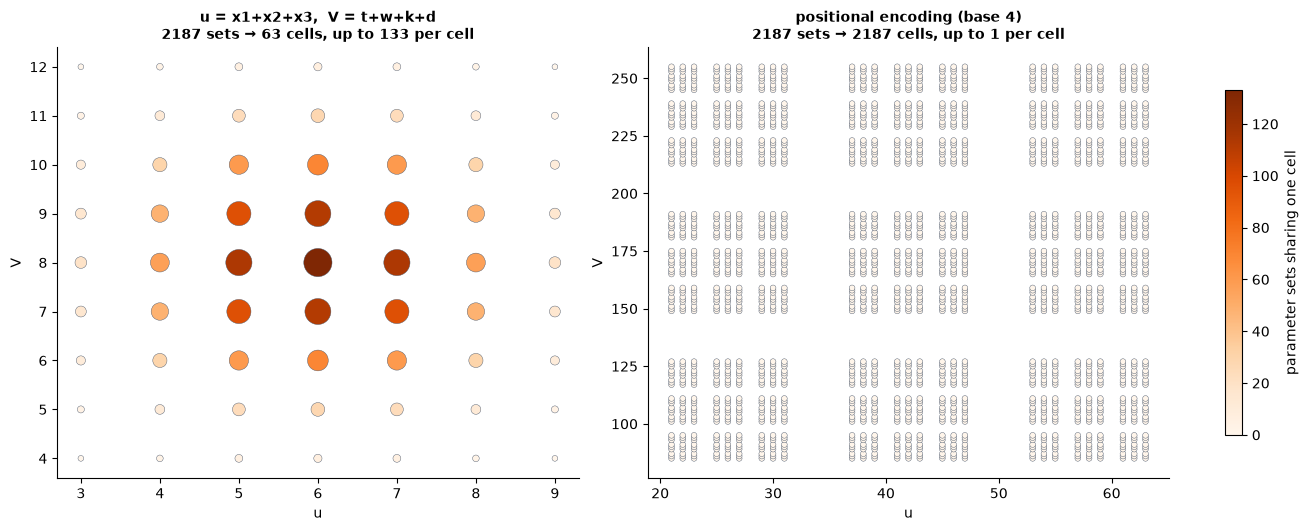

In [9]:
from collections import Counter

load_sum = Counter((t.u, t.V_global) for t in sum_map.targets(params))
load_dig = Counter((t.u, t.V_global) for t in digit_map.targets(params))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)
for ax, load, title in ((axes[0], load_sum, "u = x1+x2+x3,  V = t+w+k+d"),
                        (axes[1], load_dig, f"positional encoding (base {B})")):
    us = [k[0] for k in load]
    Vs = [k[1] for k in load]
    sizes = [load[k] for k in load]
    sc = ax.scatter(us, Vs, s=[14 + 3 * s for s in sizes], c=sizes, cmap="Oranges", vmin=0,
                    vmax=max(load_sum.values()), edgecolor="#475569", lw=0.3)
    ax.set_xlabel("u")
    ax.set_ylabel("V")
    worst = max(sizes)
    ax.set_title(f"{title}\n{len(params)} sets → {len(load)} cells, up to {worst} per cell", fontsize=10)
fig.colorbar(sc, ax=axes, label="parameter sets sharing one cell", shrink=0.8)
plt.show()

**What happened?** With sums, the 2187 parameter sets crowd onto a few dozen cells – in the
middle well over a hundred experiments would compete for one cell (the large dark circles). The positional encoding (like digits of a number in base
`B`) keeps every parameter recoverable, so every set gets its own cell. The cell numbers `N`
never collide; **only a formula that forgets information does**. A run id (`u = run_id`) is the
simplest unique alternative when the parameters are not small integers.

## 5 · Decimal inputs and the NL/NR pair

**Question:** Addresses must be integers. What about measured inputs such as `21.375 °C` – and
where do we keep units and precision?

**Minimal explanation:**

* Turn decimal inputs into integers **reversibly**: `Decimal("21.375") × 10³ = 21375`. Never go
  through `float` – binary floating point cannot represent most decimals exactly.
* Results may be anything a payload type can hold. Here we store exact decimal strings.
* The **NL/NR pair**: the same `(u, v)` has two cells. We put the value on NL and its metadata
  (scale, unit, method) on NR – by making the lane a parameter (`side = s`).

In [10]:
print("float pitfall: 0.1 + 0.2 =", 0.1 + 0.2, "  Decimal:", Decimal("0.1") + Decimal("0.2"))

SCALE = 3                                         # three decimal places
OFFSET = 300_000                                  # keeps V > 0 for temperatures down to −300 °C


def to_int(text):
    return int(Decimal(text).scaleb(SCALE)) + OFFSET


def from_int(i):
    return (Decimal(i - OFFSET).scaleb(-SCALE)).normalize()


inputs = ["21.375", "-3.125", "0.001", "99.999", "37.000"]
for t in inputs:
    assert from_int(to_int(t)) == Decimal(t)        # exact round trip
print("input → integer coordinate:", {t: to_int(t) for t in inputs})

float pitfall: 0.1 + 0.2 = 0.30000000000000004   Decimal: 0.3
input → integer coordinate: {'21.375': 321375, '-3.125': 296875, '0.001': 300001, '99.999': 399999, '37.000': 337000}


In [11]:
# Experiment: a tiny reaction model; the result is an exact rational value written as a decimal.
def reaction_rate(temp):
    k = Decimal("0.0021") * (temp + Decimal("273.15"))
    return (k * k).quantize(Decimal("0.000001"))


pair_map = MathMap.compile("measurements", ("T", "s"), u="1", V="T", side="s")
PAIR = db_path("measurements.nhydb")
with nhydb.create(PAIR) as db:
    db.create_math_layout(MathMapLayoutSpec("measurements", pair_map, 64), layout_id=1, payload_type="utf8")
    rows = []
    for t in inputs:
        T = to_int(t)
        rows.append(((T, 0), str(reaction_rate(Decimal(t)))))                       # NL: the value
        rows.append(((T, 1), f"unit=1/s scale=6 input={t}°C model=v1"))           # NR: metadata
    db.put_math_batch(1, rows, commit=True)

table = []
with nhydb.open(PAIR) as db:
    for t in inputs:
        T = to_int(t)
        nl, nr = db.get_math_cell(1, (T, 0)), db.get_math_cell(1, (T, 1))
        assert (nl["_u"], nl["_v"]) == (nr["_u"], nr["_v"]) and (nl["_lane_name"], nr["_lane_name"]) == ("NL", "NR")
        assert Decimal(nl["value"]) == reaction_rate(Decimal(t))
        table.append({"input °C": t, "(u, v)": (nl["_u"], nl["_v"]),
                      "N (NL)": nhydb.dynadron_n(nl["_realm"], nl["_u"], nl["_v"], 0),
                      "NL: value": nl["value"],
                      "N (NR)": nhydb.dynadron_n(nr["_realm"], nr["_u"], nr["_v"], 1),
                      "NR: metadata": nr["value"]})
pd.DataFrame(table).set_index("input °C")

,"(u, v)",N (NL),NL: value,N (NR),NR: metadata
input °C,,,,,
21.375,"(1, 321375)",103282533375,0.382545,103282854751,unit=1/s scale=6 input=21.375°C model=v1
-3.125,"(1, 296875)",88135359375,0.321549,88135656251,unit=1/s scale=6 input=-3.125°C model=v1
0.001,"(1, 300001)",90001200003,0.329037,90001500005,unit=1/s scale=6 input=0.001°C model=v1
99.999,"(1, 399999)",159999999999,0.614049,160000399999,unit=1/s scale=6 input=99.999°C model=v1
37.000,"(1, 337000)",113569674000,0.424211,113570011001,unit=1/s scale=6 input=37.000°C model=v1


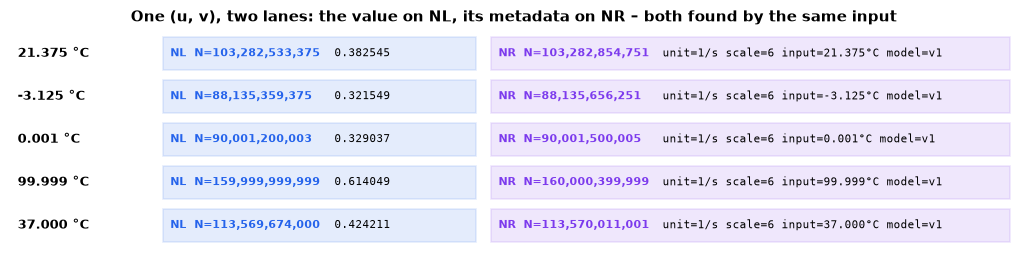

In [12]:
fig, ax = plt.subplots(figsize=(13, 2.9))
boxes = (("NL", 1.9, 4.1, "NL: value"), ("NR", 6.2, 6.8, "NR: metadata"))
for i, row in enumerate(table):
    ax.text(0, -i - 0.45, f"{row['input °C']} °C", fontsize=9, va="center", fontweight="bold")
    for lane, x0, width, key in boxes:
        ax.add_patch(Rectangle((x0, -i - 0.85), width, 0.78, facecolor=COLORS[lane], alpha=0.12,
                               edgecolor=COLORS[lane], lw=1.2))
        ax.text(x0 + 0.1, -i - 0.45, f"{lane}  N={row['N (' + lane + ')']:,}", fontsize=8, color=COLORS[lane],
                fontweight="bold", va="center")
        ax.text(x0 + 2.25, -i - 0.45, row[key], fontsize=8, va="center", family="monospace")
ax.set_xlim(-0.1, 13.1)
ax.set_ylim(-len(table) - 0.1, 0.1)
ax.axis("off")
ax.set_title("One (u, v), two lanes: the value on NL, its metadata on NR – both found by the same input")
plt.show()

**What happened?** Each measurement occupies one `(u, v)` with **two cells**: the exact result
on NL and the description on NR. Reading needs only the input temperature – converted with the
same reversible scaling – and the lane.

## Your turn

**Task:** a colleague wants to know the NR prime count of group `G = 300` and whether it was
computed in the first or the second run. Read it from the database without recomputing, then
check it.

In [13]:
with nhydb.open(PATH) as db:
    stored = db.get_math(1, (300, 1))
print(f"NR primes of G = 300: {stored}  (computed by {computed_by[300]})")
assert stored == prime_census(300)[1]

NR primes of G = 300: 32  (computed by run 2 (resume))


## ⏩ Advanced: results in very large parameter spaces

Parameters can be huge integers – a run id with 50 digits or `V` values beyond one realm. The
engine maps logical realms to free physical realms automatically (notebook 07); the budget
`realm_auto_limit` (here 64) stops a formula from claiming too many realms by mistake.

In [14]:
big_map = MathMap.compile("big_runs", ("run",), u="run % 1000 + 1", V="run // 1000 + 1", side="NL")
runs = [10**49 + i for i in range(3)] + [7 * 10**120 + 5]
rep = dry_run(big_map, [(r,) for r in runs])
print("logical realms needed:", len(rep.logical_realms), "– collisions:", rep.collisions)
with nhydb.create(db_path("big_runs.nhydb")) as db:
    db.create_math_layout(MathMapLayoutSpec("big_runs", big_map, 64), layout_id=1, payload_type="utf8")
    db.put_math_batch(1, [((r,), f"result of run {str(r)[:6]}…") for r in runs], commit=True)
    assert all(db.get_math(1, (r,)) is not None for r in runs)
    print(db.describe_math(1)["realm_extents"])

logical realms needed: 2 – collisions: 0
[{'logical_start': 1, 'logical_end': 1, 'physical_start': 1, 'physical_end': 1}, {'logical_start': 700000000000000001, 'logical_end': 700000000000000001, 'physical_start': 2, 'physical_end': 2}]


## Summary

* *MATH_LONG* is a pattern, not an API: parameters or run ids give the address, the computed result is the payload.
* Stage-wise commits make long computations crash-safe; resuming means asking `get_math` which parameters are missing.
* Re-running gives a conflict instead of a duplicate; `overwrite=True` creates a new state (the old one stays in the file).
* Sums of parameters collide; a positional encoding or a run id keeps every parameter set unique – check with `dry_run`.
* Decimal inputs become integers by exact scaling; the NL/NR pair keeps value and metadata on one `(u, v)`.

## Where to go next

* [07 · Huge Addresses](07_realms_and_huge_numbers_v1.ipynb) – realms, logical vs. physical, 200-digit numbers.
* [11 · What Actually Lives on Disk?](11_what_lives_on_disk_v1.ipynb) – commits, crashes and append-only in detail.

**Cookbook sections:** 5 (Commit and crash behavior), 18 (MATH_MAP) in the [NHyDB Python Cookbook](https://github.com/nhydb/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [15]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
